In [1]:
'''Use Random Search to efficiently explore large hyperparameter spaces in ensemble models, 
accelerating the tuning process while maintaining model performance for admission prediction.'''

'Use Random Search to efficiently explore large hyperparameter spaces in ensemble models, \naccelerating the tuning process while maintaining model performance for admission prediction.'

In [2]:
# importing libraries
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import randint, uniform

In [3]:
# loading dataset
df = pd.read_csv('Adm.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [4]:
# inspecting dataset information and summary statistics
print(df.shape)
print(df.info())
print(df.describe())

(1000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Serial No.            1000 non-null   int64  
 1   GRE Score             1000 non-null   int64  
 2   TOEFL Score           1000 non-null   int64  
 3   University Rating     1000 non-null   int64  
 4   SOP                   1000 non-null   float64
 5   LOR                   1000 non-null   float64
 6   CGPA                  1000 non-null   float64
 7   Research              1000 non-null   int64  
 8   Chance of Admit       1000 non-null   float64
 9   Application_DateTime  1000 non-null   object 
 10  University_Name       1000 non-null   object 
 11  region                1000 non-null   object 
dtypes: float64(4), int64(5), object(3)
memory usage: 93.9+ KB
None
        Serial No.    GRE Score  TOEFL Score  University Rating          SOP  \
count  1000.000000  1

In [5]:
# selecting features and admission outcome target
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = df['Chance of Admit']
print(X.head())

   GRE Score  TOEFL Score  University Rating  SOP  LOR  CGPA  Research
0        337          118                  4  4.5  4.5  9.65         1
1        324          107                  4  4.0  4.5  8.87         1
2        316          104                  3  3.0  3.5  8.00         1
3        322          110                  3  3.5  2.5  8.67         1
4        314          103                  2  2.0  3.0  8.21         0


In [6]:
# splitting dataset into train and test partitions
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(800, 7) (200, 7)


In [7]:
# standardizing feature sets
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [8]:
# training baseline ensemble models with default hyperparameters
baseline_models = {
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'Extra Trees': ExtraTreesRegressor(random_state=42)
}

baseline_records = []
for name, model in baseline_models.items():
    start_time = time.time()
    model.fit(X_train_scaled, y_train)
    train_time = time.time() - start_time
    
    y_pred = model.predict(X_test_scaled)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    baseline_records.append({
        'Model': name,
        'Baseline R2': r2,
        'Baseline RMSE': rmse,
        'Baseline MAE': mae,
        'Train Time (s)': train_time
    })

baseline_df = pd.DataFrame(baseline_records)
print(baseline_df.to_string(index=False))

            Model  Baseline R2  Baseline RMSE  Baseline MAE  Train Time (s)
    Random Forest     0.908178       0.030661      0.023388        0.298156
Gradient Boosting     0.926920       0.027353      0.021384        0.084204
      Extra Trees     0.909791       0.030390      0.023539        0.160643


In [9]:
# defining large hyperparameter distributions using scipy stats
search_spaces = {
    'Random Forest': {
        'model': RandomForestRegressor(random_state=42),
        'params': {
            'n_estimators': randint(50, 300),
            'max_depth': randint(3, 15),
            'min_samples_split': randint(2, 15),
            'min_samples_leaf': randint(1, 10),
            'max_features': ['sqrt', 'log2', None]
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingRegressor(random_state=42),
        'params': {
            'n_estimators': randint(50, 300),
            'learning_rate': uniform(0.01, 0.2),
            'max_depth': randint(2, 8),
            'min_samples_split': randint(2, 12),
            'subsample': uniform(0.6, 0.4)
        }
    },
    'Extra Trees': {
        'model': ExtraTreesRegressor(random_state=42),
        'params': {
            'n_estimators': randint(50, 300),
            'max_depth': randint(3, 15),
            'min_samples_split': randint(2, 15),
            'min_samples_leaf': randint(1, 10),
            'max_features': ['sqrt', 'log2', None]
        }
    }
}

In [10]:
# performing randomized search across ensemble models
random_search_results = {}
tuning_records = []

for name, config in search_spaces.items():
    print('Running Random Search for:', name)
    start_time = time.time()
    rs = RandomizedSearchCV(
        estimator=config['model'],
        param_distributions=config['params'],
        n_iter=25,
        cv=5,
        scoring='r2',
        random_state=42,
        n_jobs=-1
    )
    rs.fit(X_train_scaled, y_train)
    search_time = time.time() - start_time
    
    random_search_results[name] = rs
    tuning_records.append({
        'Model': name,
        'Best CV R2': rs.best_score_,
        'Search Time (s)': search_time,
        'Best Params': rs.best_params_
    })

tuning_df = pd.DataFrame(tuning_records)
print(tuning_df[['Model', 'Best CV R2', 'Search Time (s)']].to_string(index=False))

Running Random Search for: Random Forest
Running Random Search for: Gradient Boosting
Running Random Search for: Extra Trees
            Model  Best CV R2  Search Time (s)
    Random Forest    0.906372        13.722259
Gradient Boosting    0.936715         3.134523
      Extra Trees    0.917273         2.280033


In [11]:
# evaluating tuned ensemble models on test set
tuned_eval_records = []
tuned_predictions = {}

for name, rs in random_search_results.items():
    best_model = rs.best_estimator_
    y_pred = best_model.predict(X_test_scaled)
    tuned_predictions[name] = y_pred
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    
    tuned_eval_records.append({
        'Model': name,
        'Tuned Test R2': r2,
        'Tuned Test RMSE': rmse,
        'Tuned Test MAE': mae
    })

tuned_df = pd.DataFrame(tuned_eval_records)
print(tuned_df.to_string(index=False))

            Model  Tuned Test R2  Tuned Test RMSE  Tuned Test MAE
    Random Forest       0.904863         0.031209        0.024047
Gradient Boosting       0.927427         0.027258        0.021543
      Extra Trees       0.909707         0.030404        0.023980


In [12]:
# comparing baseline versus tuned ensemble performance
comparison_df = pd.merge(
    baseline_df[['Model', 'Baseline R2', 'Baseline RMSE', 'Baseline MAE']],
    tuned_df[['Model', 'Tuned Test R2', 'Tuned Test RMSE', 'Tuned Test MAE']],
    on='Model'
)
comparison_df['R2 Improvement'] = comparison_df['Tuned Test R2'] - comparison_df['Baseline R2']
comparison_df['RMSE Reduction'] = comparison_df['Baseline RMSE'] - comparison_df['Tuned Test RMSE']
print(comparison_df.to_string(index=False))

            Model  Baseline R2  Baseline RMSE  Baseline MAE  Tuned Test R2  Tuned Test RMSE  Tuned Test MAE  R2 Improvement  RMSE Reduction
    Random Forest     0.908178       0.030661      0.023388       0.904863         0.031209        0.024047       -0.003315       -0.000549
Gradient Boosting     0.926920       0.027353      0.021384       0.927427         0.027258        0.021543        0.000507        0.000095
      Extra Trees     0.909791       0.030390      0.023539       0.909707         0.030404        0.023980       -0.000085       -0.000014


In [13]:
# displaying best hyperparameter configurations found
for name, rs in random_search_results.items():
    print(f'Best Hyperparameters for {name}')
    for param, val in rs.best_params_.items():
        print(f'{param}: {val}')
    print()

Best Hyperparameters for Random Forest
max_depth: 13
max_features: None
min_samples_leaf: 3
min_samples_split: 13
n_estimators: 104

Best Hyperparameters for Gradient Boosting
learning_rate: 0.17167946962329225
max_depth: 2
min_samples_split: 11
n_estimators: 102
subsample: 0.6923575302488596

Best Hyperparameters for Extra Trees
max_depth: 13
max_features: None
min_samples_leaf: 3
min_samples_split: 13
n_estimators: 104



In [14]:
# analyzing feature importances of best tuned ensemble model
best_ensemble_name = comparison_df.sort_values(by='Tuned Test R2', ascending=False).iloc[0]['Model']
best_ensemble_model = random_search_results[best_ensemble_name].best_estimator_

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': best_ensemble_model.feature_importances_
}).sort_values(by='Importance', ascending=False)
print(f'Feature Importances ({best_ensemble_name}):')
print(importance_df.to_string(index=False))

Feature Importances (Gradient Boosting):
          Feature  Importance
             CGPA    0.753756
        GRE Score    0.081966
      TOEFL Score    0.069818
              LOR    0.054385
         Research    0.029291
University Rating    0.007706
              SOP    0.003077


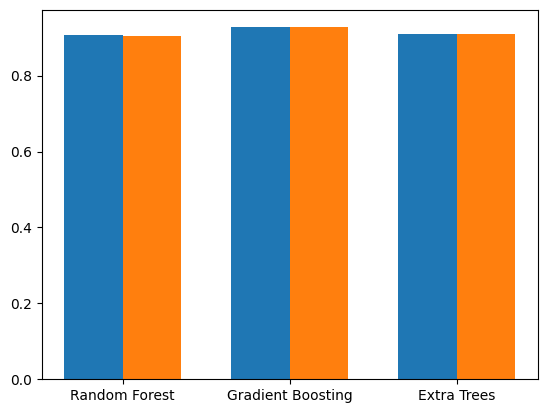

In [15]:
# plotting baseline versus tuned r2 scores
x = np.arange(len(comparison_df))
width = 0.35
plt.bar(x - width/2, comparison_df['Baseline R2'], width)
plt.bar(x + width/2, comparison_df['Tuned Test R2'], width)
plt.xticks(x, comparison_df['Model'])
plt.show()

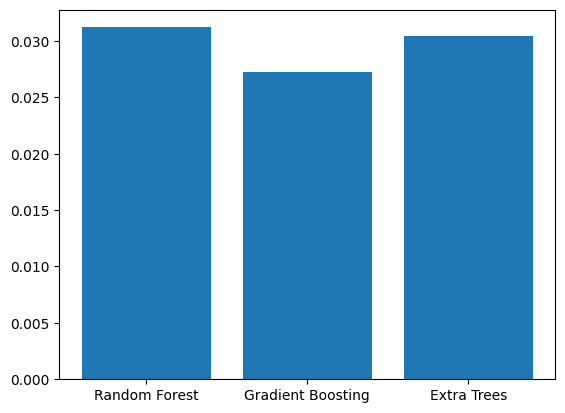

In [16]:
# plotting rmse reduction across tuned ensemble models
plt.bar(comparison_df['Model'], comparison_df['Tuned Test RMSE'])
plt.show()

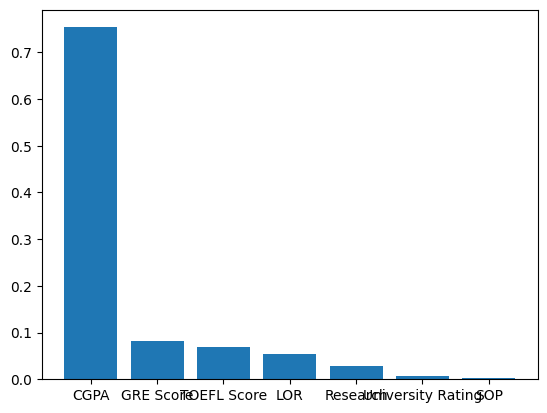

In [17]:
# plotting feature importances of best ensemble model
plt.bar(importance_df['Feature'], importance_df['Importance'])
plt.show()

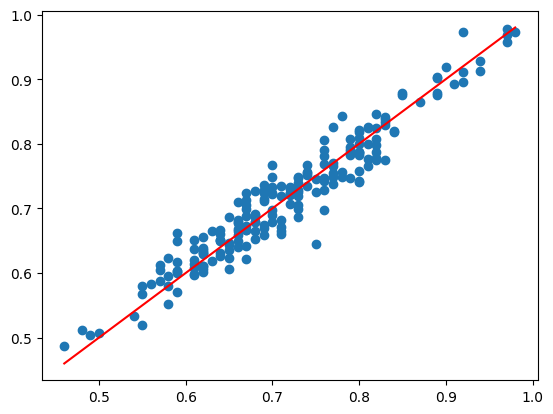

In [18]:
# plotting actual vs predicted values for best tuned ensemble model
y_best_pred = tuned_predictions[best_ensemble_name]
plt.scatter(y_test, y_best_pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red')
plt.show()

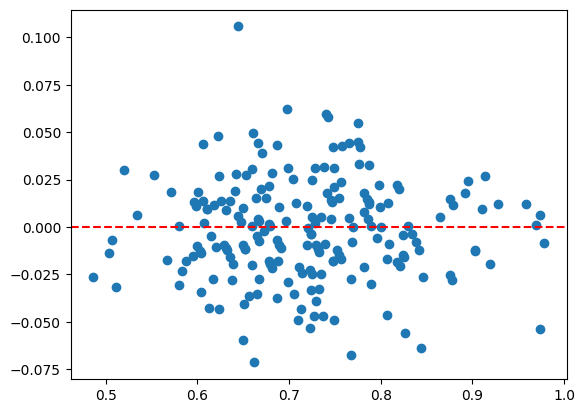

In [19]:
# plotting prediction errors of best tuned model
errors = y_test - y_best_pred
plt.scatter(y_best_pred, errors)
plt.axhline(0, color='red', linestyle='--')
plt.show()